In [1]:
import sys

clam_root = "/home/jshemons/project/TME_project/UNI/CLAM"

if clam_root not in sys.path:
    sys.path.insert(0, clam_root)

In [2]:
import torch
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import v2
import os
from skimage.color import label2rgb

import matplotlib.pyplot as plt
import warnings
import pandas as pd
import numpy as np
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans
#import hdbscan
#import umap
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
import torch
import re

import pickle
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

from CLAM.models.model_clam import CLAM_SB
from CLAM.utils.eval_utils import initiate_model
import argparse
import sys
import cv2
from captum.attr import IntegratedGradients


In [5]:
class CLAMpipe:
    def __init__(self, config):
        self.config = config

        self.project_root = config["project_root"]
        self.embedding_dir = config["embedding_dir"]
        self.top_patch_dir = config["top_patch_dir"]
        self.patch_dir = config["patch_dir"]
        self.results_dir = config["results_dir"]
        self.aligned_HE_path = config["aligned_HE_path"]

        self.df_all = None
        self.slide_id = None
        self.TMA = None
        self.label = None
        
        self.feats = None
        self.coords = None
        self.bag = None

        self.A = None
        self.A_norm = None
        self.bag_valid = None
        self.coords_valid = None
        self.A_valid = None
        self.mask = None
        self.aligned_HE = None 
        self.IG_scores = None
        self.y_hat = None
        self.Y_prob = None


    def _sorted_key(self, file_path):
        match = re.findall(r"(TMA\d+_\d+)", file_path)
        return match[0] if match else None
        
    def load_df(self):
        '''
        Simply load the dataframe, then return it
        '''
        self.df_all = pd.read_csv(self.config['df_path'], low_memory = True)

        
    def embeddings_to_pt(self, save_dir, feat_cols, np_save_dir):
        '''
        This takes all your embeddings and converts them into '.pt' files so they are usable with the CLAM model
        This is very specific to the dataframe I have created
        '''
        all_results = {}
        
        os.makedirs(save_dir, exist_ok=True)    
        
        for path, group in self.df_all.groupby('paths'):
            
            slide_name = os.path.basename(path).replace('.npy', '') ### Specific to my layout
            feats = torch.tensor(group[feat_cols].values, dtype=torch.float32)  
            patch_indices = group.index.tolist()  # original indices before dedup
            np.save(f'/projects/ag-bozek/jshemons/clam_embeddings/pt_files/{slide_name}_indices.npy', np.array(patch_indices))
            torch.save(feats, os.path.join(save_dir, f'{slide_name}.pt'))
            
            print(f"Saved {slide_name}: {feats.shape}")
    
            all_results[slide_name] = {'feats':feats,
                            'patch_indices': patch_indices}
            
        return all_results
    
    
    def class_report(self, target_names):
        '''
        This loads all the data from the pickle out file after the CLAM run
        '''
        
        all_probs = []
        all_labels = []
        all_preds = []
        
        
        
        for fold in range(3):
            pkl_path = f'CLAM/results/pT_binary_CLAM_s1/split_{fold}_results.pkl'  
    
            with open(pkl_path, 'rb') as f:
                results = pickle.load(f)
            
            for slide_id, data in results.items():
                self.slide_id = slide_id
                prob_pn1 = data['prob'][0][1]  # probability of pN1+
                label = data['label']
                pred = 1 if prob_pn1 > 0.5 else 0
                
                all_probs.append(prob_pn1)
                all_labels.append(label)
                all_preds.append(pred)
        
        self.all_probs  = np.array(all_probs)
        self.all_labels = np.array(all_labels)
        self.all_preds  = np.array(all_preds)
        
        # Metrics
        print(classification_report(all_labels, all_preds, target_names=target_names))
        print(f"Overall AUC: {roc_auc_score(all_labels, all_probs):.3f}")
            
    
    def confusion_mat(self):
        '''
        Simply plots a confusion matrix
        Returns nothing
        '''
    
        cm = confusion_matrix(self.all_labels, self.all_preds)
        
        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=['Predicted pT Low (1&2)', 'Predicted pT High (3)'],
                    yticklabels=['True pT (1&2)', 'True pT High (3)'])
        plt.title(f'Confusion Matrix - All Folds (AUC={roc_auc_score(self.all_labels, self.all_probs):.3f})')
        plt.tight_layout()
        plt.show()
    
    def load_feats_coords_per_file(self, slide_id, results_split, feats_load_path):
        """
        This loads the coords and the feats for a 
        specific file from CLAM run for visualization.
        """
    
        with open(results_split, "rb") as f:
            results = pickle.load(f)
    
        self.slide_id = slide_id
        self.TMA = self._sorted_key(slide_id)
    
        prob = results[slide_id]["prob"]
        self.label = results[slide_id]["label"]
    
        slide_df = self.df_all[self.df_all["paths"].apply(lambda p: os.path.basename(p).replace('.npy', '') == slide_id)]
    
        self.coords = slide_df[["coord_x", "coord_y"]].values
        self.feats = torch.load(feats_load_path)
    
        return {
            "slide_id": slide_id,
            "TMA": self.TMA,
            "prob": prob,
            "label": self.label,
            "coords": self.coords,
            "feats": self.feats,
        }
    
    
    def load_ckpt(self, device="cpu"):
        """
        Load CLAM checkpoint and get attention scores for self.feats.
        """
    
        sys.path.insert(0, "/home/jshemons/project/TME_project/UNI/CLAM")
    
        args = argparse.Namespace(
            model_type=self.config["model_type"],
            model_size=self.config["model_size"],
            drop_out=0.25,
            embed_dim=self.config["embed_dim"],
            n_classes=self.config["n_classes"]
        )
    
        self.model = initiate_model(
            args,
            str(self.config["ckpt_path"]),
            device=device
        )
    
        self.model.eval()
    
        self.feats = self.feats.to(device)
    
        with torch.no_grad():
            self.A = self.model(self.feats, attention_only=True)
            if self.A.dim() > 1:
                self.A = self.A.squeeze(0)
                
            self.A = self.A.cpu().numpy()
    
            logits, Y_prob, Y_hat, _, _ = self.model(self.feats)
    
        self.logits = logits
        self.Y_prob = Y_prob
        self.Y_hat = Y_hat
    
        print("Attention weights shape:", self.A.shape)
        print("Coords shape:", self.coords.shape)
        print("Should match:", self.A.shape[0] == self.coords.shape[0])
    
        return Y_prob, Y_hat


    def integrated_gradients(self, device="cpu", steps=50, target_class=None):
        self.model.eval()
    
        feats = self.feats.to(device).float()
    
        # CLAM usually expects one bag as [N_patches, embed_dim]
        if feats.dim() == 2:
            feats = feats.unsqueeze(0)  # Captum sample: [1, N_patches, embed_dim]
    
        feats.requires_grad_(True)
    
        if target_class is None:
            target_class = int(self.Y_hat.item()) if hasattr(self, "Y_hat") else 1
    
        def forward_func(x):
            outputs = []
    
            for bag in x:
                logits, Y_prob, Y_hat, _, _ = self.model(bag)
                outputs.append(logits[:, target_class])
    
            return torch.cat(outputs, dim=0)
    
        ig = IntegratedGradients(forward_func)
    
        baseline = torch.zeros_like(feats)
    
        attributions, delta = ig.attribute(
            feats,
            baselines=baseline,
            n_steps=steps,
            return_convergence_delta=True,
            internal_batch_size=1,
        )
    
        patch_scores = attributions.sum(dim=2).squeeze(0)
        self.IG_scores = patch_scores.detach().cpu().numpy()
        self.IG_delta = delta.detach().cpu().numpy()
    
        print("IG:", self.IG_scores.shape)
        print("Coords:", self.coords.shape)
        print("Target class:", target_class)
        print("Convergence delta:", self.IG_delta)
    
        return self.IG_scores

    def HE_Masked(self, mask_path, HE_path, plot=False):
        """
        This plots the nimbus mask overtop the aligned H&E image
        """
        self.aligned_HE = cv2.imread(HE_path, cv2.IMREAD_UNCHANGED)
        self.mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
        
        if plot:
            plt.imshow(self.aligned_HE)                                    
            plt.imshow(label2rgb(self.mask, bg_label=0), alpha=.6)        
            plt.axis('off')
            plt.show()

        return self.aligned_HE 
    
    def build_canvas(self, score_type = ''):
        """
        This builds the canvas to plot the patch and heatmap over top of
        """
        if score_type == "attention":
            scores = self.A
            self.scores = (scores - scores.min()) / (scores.max() - scores.min())    
            
        elif score_type == "IG":
            self.scores = self.IG_scores

        x_max = self.coords[:, 0].max() + self.config['patch_size']
        y_max = self.coords[:, 1].max() + self.config['patch_size']
        canvas = np.ones((y_max, x_max, 3), dtype=np.uint8) * 255
        
        heatmap = np.zeros((y_max, x_max))
        
        return canvas, heatmap
        
    
    def attention_map(self, mask_path, patch_path, canvas, heatmap, plot= False): 
        """
        This first plots the patch over top the canvas
        Then plots the attention weights over top of that
        """
        self.bag = np.load(patch_path)
        self.bag = (self.bag * 255).astype(np.uint8)
        for i, (x, y) in enumerate(self.coords):
            canvas[y:y+self.config['patch_size'], x:x+self.config['patch_size']] = self.bag[i]
            heatmap[y:y+self.config['patch_size'], x:x+self.config['patch_size']] = self.scores[i]
            
        # mask out background (where no patch was placed)
        heatmap_masked = np.ma.masked_where(heatmap == 0, heatmap)
                                  

        if plot:
            plt.figure(figsize=(10, 10))
            #plt.imshow(canvas)
            plt.imshow(label2rgb(self.mask, bg_label=0), alpha=.6)    

            im = plt.imshow(
                    heatmap_masked,
                    cmap="RdYlBu_r",
                    alpha=0.5,
                    interpolation="nearest",
                    vmin=np.min(self.scores),
                    vmax=np.max(self.scores)
                )
            plt.colorbar(im, label="Attention Score Importance")
    
            plt.title(f"{self.TMA} - Attention Heatmap")
            plt.axis("off")
            plt.tight_layout()
            plt.show()
    
        return canvas, heatmap

            
    def extract_top_patches(self, pixel_thresh=10.0/255, top_quantile=.75, bot_quantile=.25):
        """
        Extract top & bottom patches of each bag (H&E image) based on attention score.
        """
    
        scores_norm_arr = np.asarray(self.scores)
    
        valid_mask = self.bag.mean(axis=(1, 2, 3)) > pixel_thresh
    
        self.bag_valid = self.bag[valid_mask]
        self.coords_valid = self.coords[valid_mask]
        self.scores_valid = scores_norm_arr[valid_mask]
    
        top_k = np.quantile(self.scores_valid, q=top_quantile)
        top_indices = np.where(self.scores_valid >= top_k)[0]
        top_indices = top_indices[np.argsort(self.scores_valid[top_indices])[::-1]]

        bot_k = np.quantile(self.scores_valid, q=bot_quantile)
        bot_indices = np.where(self.scores_valid <= bot_k)[0]
        bot_indices = bot_indices[np.argsort(self.scores_valid[bot_indices])]
        
        return top_indices, top_k, bot_indices, bot_k

    def get_top_IG_scores(self, Y_hat, pixel_thresh=10.0/255, top_quantile=.75, bot_quantile = .25, ):
        """
        This gets the probabilites for each TMA, it then does a boolean asking: If the TMA is predicted to be 1, then
        which IG scores most support that prediction and which IG scores least support that prediction, those patches are then saved.
        ONLY WORKS WITH IG scores (check to make sure the score type in def build_canvas)
        """
        scores_norm_arr = np.asarray(self.scores)
    
        valid_mask = self.bag.mean(axis=(1, 2, 3)) > pixel_thresh
    
        self.bag_valid = self.bag[valid_mask]
        self.coords_valid = self.coords[valid_mask]
        self.scores_valid = scores_norm_arr[valid_mask]

        Y_hat = int(self.Y_hat.item())
        print(f'The predicted value for this H&E is {Y_hat}')
        if Y_hat == 1:
            top_k = np.quantile(self.scores_valid, q=top_quantile)
            bot_k = np.quantile(self.scores_valid, q=bot_quantile)
        
            top_indices = np.where(self.scores_valid >= top_k)[0]
            bot_indices = np.where(self.scores_valid <= bot_k)[0]
        
            top_indices = top_indices[np.argsort(self.scores_valid[top_indices])[::-1]]
            bot_indices = bot_indices[np.argsort(self.scores_valid[bot_indices])]
        
        elif Y_hat == 0:
            top_k = np.quantile(self.scores_valid, q=1 - top_quantile)
            bot_k = np.quantile(self.scores_valid, q=1 - bot_quantile)
        
            top_indices = np.where(self.scores_valid <= top_k)[0]
            bot_indices = np.where(self.scores_valid >= bot_k)[0]
        
            top_indices = top_indices[np.argsort(self.scores_valid[top_indices])]
            bot_indices = bot_indices[np.argsort(self.scores_valid[bot_indices])[::-1]]
                
        return top_indices, top_k, bot_indices, bot_k

        
    def plt_top_patches(self, top_indices, bot_indices, Y_hat):
        """
        Plot top patches based on attention score.
        """

        top_indices = top_indices[:10]
        bot_indices = bot_indices[:10]
        
        ncols = max(len(top_indices), len(bot_indices))
        fig, axes = plt.subplots(2, ncols, figsize=(3 * ncols, 6))
        
        if ncols == 1:
            axes = axes.reshape(2, 1)
        
        for rank, idx in enumerate(top_indices):
            patch = self.bag_valid[idx]
        
            axes[0, rank].imshow(patch)
            axes[0, rank].set_title(
                f"Top {rank + 1}\n"
                f"IG: {self.scores_valid[idx]:.3f}\n"
                f"Coords: {self.coords_valid[idx]}"
            )
            axes[0, rank].axis("off")
        
        for rank, idx in enumerate(bot_indices):
            patch = self.bag_valid[idx]
        
            axes[1, rank].imshow(patch)
            axes[1, rank].set_title(
                f"Bottom {rank + 1}\n"
                f"IG: {self.scores_valid[idx]:.3f}\n"
                f"Coords: {self.coords_valid[idx]}"
            )
            axes[1, rank].axis("off")
        
        for row in range(2):
            for col in range(ncols):
                if col >= len(top_indices) and row == 0:
                    axes[row, col].axis("off")
                if col >= len(bot_indices) and row == 1:
                    axes[row, col].axis("off")
        
        plt.suptitle(
            f"{self.slide_id} | "
            f"Label: {'pT Low' if self.label == 0 else 'pT High'} | "
            f"Pred: {Y_hat.item() if hasattr(Y_hat, 'item') else Y_hat}"
        )
        
        plt.tight_layout()
        plt.show()
    
    
    def save_top_patches(self, top_indices, save_dir, csv_save_path):
        """
        Save top patches and metadata.
        """
    
        os.makedirs(save_dir, exist_ok=True)
    
        saved = []
    
        for rank, idx in enumerate(top_indices):
            patch = self.bag_valid[idx]
            coord = self.coords_valid[idx]
            attn = self.scores_valid [idx]
    
            patch_save_path = os.path.join(save_dir, f"rank_{rank}_patch.npy")
            np.save(patch_save_path, patch)
    
            saved.append({
                "rank": rank,
                "index_in_valid": int(idx),
                "coord_x": int(coord[0]),
                "coord_y": int(coord[1]),
                "attention/IG": float(attn),
                "patch_path": patch_save_path,
            })
    
        pd.DataFrame(saved).to_csv(csv_save_path, index=False)
    
        return saved

    def save_bot_patches(self, bot_indices, save_dir, csv_bot_save_path):
        """
        Save bottom patches and metadata.
        """
    
        os.makedirs(save_dir, exist_ok=True)
    
        saved = []
    
        for rank, idx in enumerate(bot_indices):
            patch = self.bag_valid[idx]
            coord = self.coords_valid[idx]
            attn = self.scores_valid [idx]
    
            patch_save_path = os.path.join(save_dir, f"rank_{rank}_patch.npy")
            np.save(patch_save_path, patch)
    
            saved.append({
                "rank": rank,
                "index_in_valid": int(idx),
                "coord_x": int(coord[0]),
                "coord_y": int(coord[1]),
                "attention/IG": float(attn),
                "patch_path": patch_save_path,
            })
      
        pd.DataFrame(saved).to_csv(csv_bot_save_path, index=False)
    
        return saved

In [21]:
from pathlib import Path

config = {
    "project_root": Path("/projects/ag-bozek/jshemons"),
    "embedding_dir": Path("/projects/ag-bozek/jshemons/clam_embeddings/pt_files"),
    "top_patch_dir": Path("/projects/ag-bozek/jshemons/top_patches"),
    "bot_patch_dir": Path("/projects/ag-bozek/jshemons/bot_patches"),
    "patch_dir": Path("/projects/ag-bozek/jshemons/patched_HE"),
    "mask_dir": Path("Nimbus-Inference/templates/data/real_dataset/pixie/real_cell_output_dir_generic/cell_masks"),
    "df_path": Path("embedding_df_pT_central.csv"), ### this is important, its the DF where all the embeddings are located. It passes through to the function at the bottom.
    "aligned_HE_path" : Path("/projects/ag-bozek/mcarval3/notebooks_martim/Example_notebooks_Jared/tiff_DAPI_HNE"),
    "results_dir": Path("CLAM/results/pT_binary_CLAM_s1"),
    "ckpt_path": Path("CLAM/results/pT_binary_CLAM_s1/s_0_checkpoint.pt"),

    "patch_size": 224,
    "n_folds": 5, ### Dont forget this dude, super important otherwise you will miss a fold
    "model_type": "clam_sb",
    "model_size": "uni",
    "n_classes": 2,
    "embed_dim": 1536,
    "device": "cpu",
}

pipe = CLAMpipe(config)
pipe.load_df()

In [23]:
with open(config["results_dir"] / "split_4_results.pkl", "rb") as f:
    fold4 = pickle.load(f)

fold4_only = set(fold4.keys())
for fold in range(4):
    with open(config["results_dir"] / f"split_{fold}_results.pkl", "rb") as f:
        other = pickle.load(f)
    fold4_only -= set(other.keys())

print(f"{len(fold4_only)} slides exist ONLY in fold 4 and were being silently skipped")

28 slides exist ONLY in fold 4 and were being silently skipped


In [28]:
def sorted_key(file_path):
    match = re.findall(r"(TMA\d+_\d+)", file_path)
    return match[0] if match else None

unique_slides = pipe.df_all['paths'].apply(lambda x: os.path.basename(x).replace('.npy', '')).unique()
unique_slides

TMA_y_hat = []
for slide_name in unique_slides:
    slide_id = slide_name
    TMA = sorted_key(slide_id)   
    # --- NEW: Dynamic Split Finder --- # This is used strictly to cycle through all the splits
    found_split_path = None
    for fold in range(config.get("n_folds")):
        potential_split = config["results_dir"] / f"split_{fold}_results.pkl"
        
        if potential_split.exists():
            with open(potential_split, "rb") as f:
                temp_results = pickle.load(f)
            if slide_id in temp_results:
                found_split_path = potential_split
                print(f"  -> Found slide in fold {fold}")
                break
                
    if found_split_path is None:
        print(f"Error: {slide_id} was not found in any of the split results pkl files. Skipping.")
        continue
        
    feats_load_path = f"{config['embedding_dir']}/{slide_id}.pt"
    
    loaded = pipe.load_feats_coords_per_file(
        slide_id=slide_id,
        results_split=found_split_path,
        feats_load_path=feats_load_path
    )
    Y_prob, Y_hat = pipe.load_ckpt(device="cpu")
    
    TMA_y_hat.append({'Y_prob': Y_prob, 
                      'TMA': TMA})

    
    mask_path = config["mask_dir"] / f"{TMA}_cell_mask.tiff"
    aligned_HE_path = config["aligned_HE_path"] / f"{TMA}_HNE_aligned.tiff"
    
    pipe.HE_Masked(mask_path, aligned_HE_path, plot = False)
    
    patch_path = config["patch_dir"] / f"{TMA}_patches.npy"
    
    pipe.integrated_gradients()
    print("A shape:", pipe.A.shape, "IG shape:", pipe.IG_scores.shape)
    print("Are they identical?", np.array_equal(pipe.A, pipe.IG_scores))
    print("Correlation:", np.corrcoef(pipe.A, pipe.IG_scores)[0,1])

    canvas, heatmap = pipe.build_canvas(score_type="IG")
    pipe.attention_map(mask_path, patch_path, canvas, heatmap, plot = False)

    ### Only call 'extract_top_patches' if you are using attention scores (check build_canvas)
    #top_indices, top_k, bot_indices, bot_k = pipe.extract_top_patches(pixel_thresh=10.0/255, top_quantile=.75, bot_quantile=.25) ### Remember the 255 because the output in the patch extraction was normalized
    top_indices, top_k, bot_indices, bot_k = pipe.get_top_IG_scores(Y_hat, pixel_thresh=10.0/255, top_quantile=.75, bot_quantile=.25) 

    #pipe.plt_top_patches(top_indices, bot_indices, Y_hat)
    slide_save_dir = config["top_patch_dir"] / TMA
    bot_slide_save_dir = config["bot_patch_dir"] / TMA

    slide_csv_path = slide_save_dir / "top_patches.csv"
    slide_bot_csv_path = bot_slide_save_dir / "bot_patches.csv"
    
    pipe.save_top_patches(
        top_indices=top_indices, 
        save_dir=slide_save_dir, 
        csv_save_path=slide_csv_path
    ) 
    pipe.save_bot_patches(
        bot_indices=bot_indices, 
        save_dir=bot_slide_save_dir, 
        csv_bot_save_path=slide_bot_csv_path
    ) 
    
    print(f"Successfully processed and isolated top patches for {slide_id}") 
    

  -> Found slide in fold 4
Init Model
CLAM_SB(
  (attention_net): Sequential(
    (0): Linear(in_features=1536, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.25, inplace=False)
    (3): Attn_Net_Gated(
      (attention_a): Sequential(
        (0): Linear(in_features=512, out_features=256, bias=True)
        (1): Tanh()
        (2): Dropout(p=0.25, inplace=False)
      )
      (attention_b): Sequential(
        (0): Linear(in_features=512, out_features=256, bias=True)
        (1): Sigmoid()
        (2): Dropout(p=0.25, inplace=False)
      )
      (attention_c): Linear(in_features=256, out_features=1, bias=True)
    )
  )
  (classifiers): Linear(in_features=512, out_features=2, bias=True)
  (instance_classifiers): ModuleList(
    (0-1): 2 x Linear(in_features=512, out_features=2, bias=True)
  )
  (instance_loss_fn): CrossEntropyLoss()
)
Total number of parameters: 1052935
Total number of trainable parameters: 1052935
Attention weights shape: (645,)
Coords shape: (645

In [ ]:
slide_id = "TMA0_67_patches"
TMA = "TMA0_67"
fold = 0

results_split = config["results_dir"] / f"split_{fold}_results.pkl"
feats_load_path = config["embedding_dir"] / f"{slide_id}.pt"
patch_path = config["patch_dir"] / f"{TMA}_patches.npy"
indices_dir = config["embedding_dir"] / f'{TMA}_indices.npy'
top_patch_save_dir = config["top_patch_dir"] / TMA
top_patch_csv_path = top_patch_save_dir / "top_patches.csv"

ckpt_path = config["ckpt_path"]

target_names = ["pT Low", "pT High"]
save_path = Path("confusion_matrix_8020_central.png")

Saved TMA0_20_patches: torch.Size([590, 1536])
Saved TMA0_21_patches: torch.Size([612, 1536])
Saved TMA0_22_patches: torch.Size([618, 1536])
Saved TMA0_23_patches: torch.Size([624, 1536])
Saved TMA0_46_patches: torch.Size([630, 1536])
Saved TMA0_47_patches: torch.Size([717, 1536])
Saved TMA0_60_patches: torch.Size([614, 1536])
Saved TMA0_61_patches: torch.Size([646, 1536])
Saved TMA0_62_patches: torch.Size([644, 1536])
Saved TMA0_65_patches: torch.Size([708, 1536])
Saved TMA0_67_patches: torch.Size([589, 1536])
Saved TMA0_68_patches: torch.Size([671, 1536])
Saved TMA0_70_patches: torch.Size([704, 1536])
Saved TMA0_87_patches: torch.Size([583, 1536])
Saved TMA0_88_patches: torch.Size([585, 1536])
Saved TMA0_8_patches: torch.Size([227, 1536])
Saved TMA0_90_patches: torch.Size([584, 1536])
Saved TMA0_92_patches: torch.Size([683, 1536])
Saved TMA0_93_patches: torch.Size([686, 1536])
Saved TMA0_95_patches: torch.Size([667, 1536])
Saved TMA0_97_patches: torch.Size([582, 1536])
Saved TMA0_98_

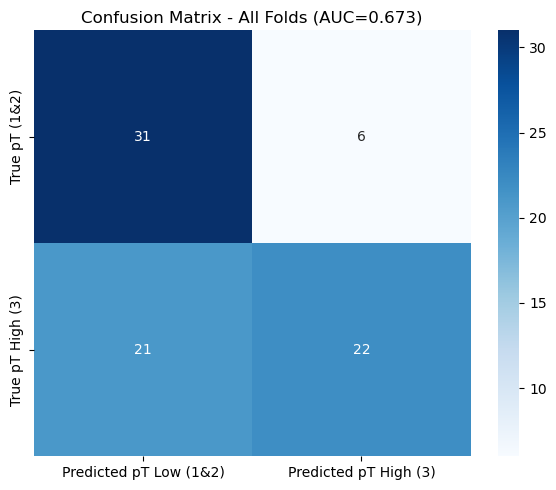

In [12]:
## Save the embeddings extracted from UNI
feat_cols = [
    c for c in pipe.df_all.columns
    if c not in ["label", "patient_id", "paths", "Unnamed: 0", "coord_x", "coord_y"]
]

pipe.embeddings_to_pt(config['embedding_dir'], feat_cols, indices_dir)

### Save the organized dataset information 
df_meta = pipe.df_all.groupby('paths')[['label', 'patient_id']].first().reset_index()
df_meta['slide_id'] = df_meta['paths'].apply(lambda x: os.path.basename(x).replace('.npy', ''))
df_meta['case_id']  = df_meta['patient_id']

# Binarize: pT0 vs rest
df_meta['label'] = df_meta['label'].map({1: 'pT_grade_low', 2: 'pT_grade_low', 3: 'pT_grade_high'})

print(df_meta['label'].value_counts())
df_meta1 = df_meta[['case_id', 'slide_id', 'label']]
df_meta1 = df_meta1.dropna(subset = ['label'])
df_meta1[['case_id', 'slide_id', 'label']].to_csv(
    '/home/jshemons/project/TME_project/UNI/dataset_csv.csv', index=False)
#####

### Plot Confusion Matrix
pipe.class_report(target_names)
pipe.confusion_mat()

In [16]:
### Load the coords and attention weights
slide_id = "TMA0_67_patches"

results_split = f"{config['results_dir']}/split_0_results.pkl"
feats_load_path = f"{config['embedding_dir']}/{slide_id}.pt"

loaded = pipe.load_feats_coords_per_file(
    slide_id=slide_id,
    results_split=results_split,
    feats_load_path=feats_load_path
)

In [17]:
print(pipe.feats.shape)
print(pipe.coords.shape)

torch.Size([496, 1536])
(496, 2)


In [18]:
### Load the checkpoints and the models 
Y_prob, Y_hat = pipe.load_ckpt(device="cpu")

Init Model
CLAM_SB(
  (attention_net): Sequential(
    (0): Linear(in_features=1536, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.25, inplace=False)
    (3): Attn_Net_Gated(
      (attention_a): Sequential(
        (0): Linear(in_features=512, out_features=256, bias=True)
        (1): Tanh()
        (2): Dropout(p=0.25, inplace=False)
      )
      (attention_b): Sequential(
        (0): Linear(in_features=512, out_features=256, bias=True)
        (1): Sigmoid()
        (2): Dropout(p=0.25, inplace=False)
      )
      (attention_c): Linear(in_features=256, out_features=1, bias=True)
    )
  )
  (classifiers): Linear(in_features=512, out_features=2, bias=True)
  (instance_classifiers): ModuleList(
    (0-1): 2 x Linear(in_features=512, out_features=2, bias=True)
  )
  (instance_loss_fn): CrossEntropyLoss()
)
Total number of parameters: 1052935
Total number of trainable parameters: 1052935
Attention weights shape: (496,)
Coords shape: (496, 2)
Should match: True


In [19]:
canvas, heatmap = pipe.build_canvas()
pipe.attention_map(patch_path, canvas, heatmap)

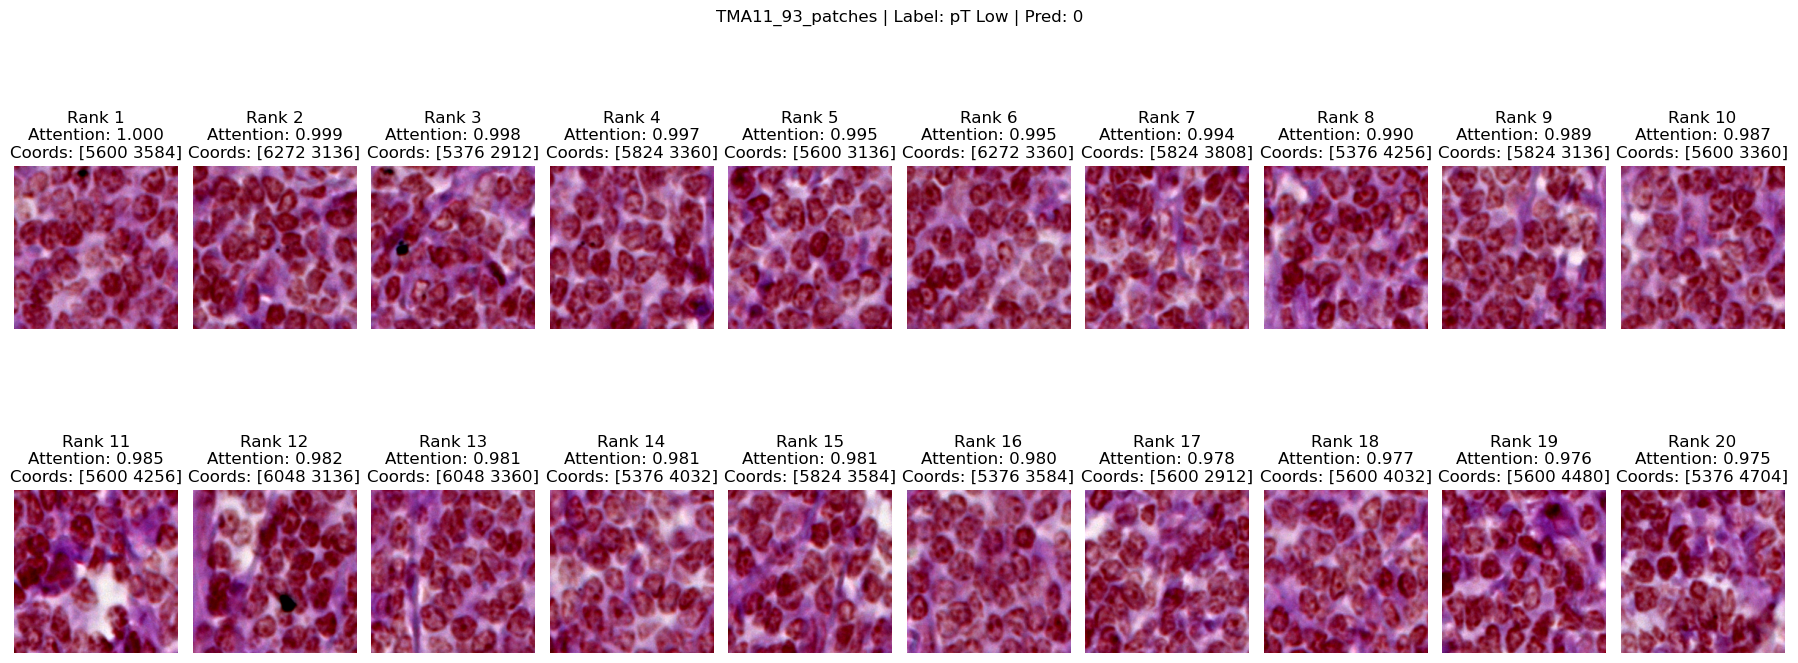

In [22]:
top_indices, top_k = pipe.extract_top_patches(pixel_thresh=10.0, top_patches=20)
pipe.plt_top_patches(top_indices, Y_hat)
#pipe.save_top_patches(top_indices, config['top_patch_dir'], config["csv_path"])

In [28]:
tmas = [sorted_key(s) for s in unique_slides]
print(len(unique_slides), len(set(tmas)))

141 141


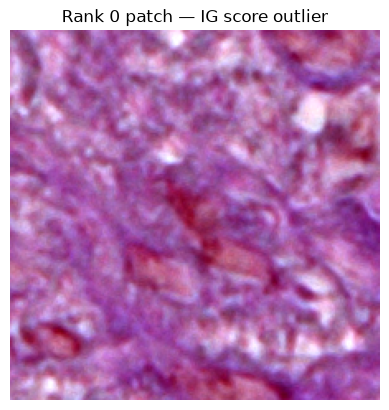

In [36]:
import matplotlib.pyplot as plt
patch = pipe.bag_valid[546]  # index_in_valid from your table
plt.imshow(patch)
plt.title("Rank 0 patch — IG score outlier")
plt.axis('off')
plt.show()

In [37]:
import numpy as np
raw_scores = pipe.IG_scores
print("max:", raw_scores.max(), "2nd max:", np.sort(raw_scores)[-2])
print("mean:", raw_scores.mean(), "std:", raw_scores.std())

max: 0.22863603 2nd max: 0.05834835
mean: 0.0008261696 std: 0.008945825
